In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Загружаем датасет
df = pd.read_csv('StudentsPerformance.csv')

# 1. Смотрим первые 5 строк и общую структуру
print("=== ПЕРВЫЕ 5 СТРОК ДАТАСЕТА ===")
display(df.head())

print("\n=== ИНФОРМАЦИЯ О СТРУКТУРЕ И ТИПАХ ДАННЫХ ===")
df.info()

# 2. Проверяем наличие пропусков (Задача 5)
print("\n=== ПРОВЕРКА НА ПРОПУСКИ ===")
print(df.isnull().sum())

# 3. Основные статистические характеристики (Задача 2)
print("\n=== СТАТИСТИЧЕСКИЕ ХАРАКТЕРИСТИКИ (ЧИСЛОВЫЕ) ===")
display(df.describe())

print("\n=== СТАТИСТИЧЕСКИЕ ХАРАКТЕРИСТИКИ (КАТЕГОРИАЛЬНЫЕ) ===")
display(df.describe(include='object'))

=== ПЕРВЫЕ 5 СТРОК ДАТАСЕТА ===


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75



=== ИНФОРМАЦИЯ О СТРУКТУРЕ И ТИПАХ ДАННЫХ ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB

=== ПРОВЕРКА НА ПРОПУСКИ ===
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000



=== СТАТИСТИЧЕСКИЕ ХАРАКТЕРИСТИКИ (КАТЕГОРИАЛЬНЫЕ) ===


,gender,race/ethnicity,parental level of education,lunch,test preparation course
count,1000,1000,1000,1000,1000
unique,2,5,6,2,2
top,female,group C,some college,standard,none
freq,518,319,226,645,642


Первичный анализ данных (EDA):
Загружен датасет StudentsPerformance.csv (1000 строк, 8 столбцов). Пропущенных значений нет (0 во всех столбцах). Признаки делятся на 5 категориальных (object) и 3 числовых (int64 — баллы за экзамены). Средние баллы: математика — 66.09, чтение — 69.17, письмо — 68.05. В столбце math score обнаружено минимальное значение 0, что указывает на наличие аномалий.

### Блок 1. Визуализация средствами Pandas
Построение базовых графиков распределения категориальных и числовых признаков напрямую из DataFrame с использованием методов `.value_counts()`, `.plot()` и `.hist()`.

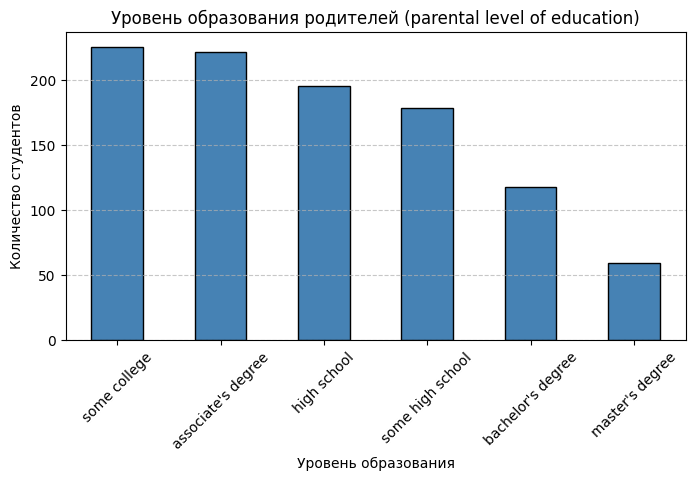

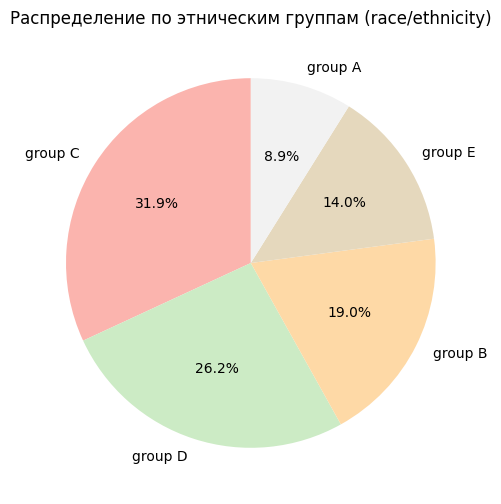

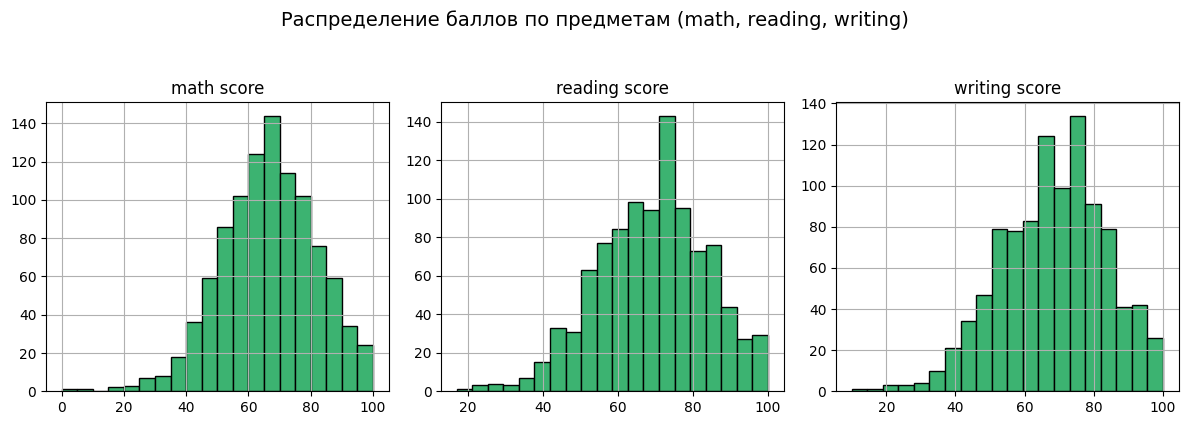

In [ ]:
# 1. Столбчатая диаграмма для parental level of education
plt.figure(figsize=(8, 4))
df['parental level of education'].value_counts().plot(
    kind='bar',
    color='steelblue',
    edgecolor='black',
    title='Уровень образования родителей (parental level of education)'
)
plt.xlabel('Уровень образования')
plt.ylabel('Количество студентов')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# 2. Круговая диаграмма для race/ethnicity
plt.figure(figsize=(6, 6))
df['race/ethnicity'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    cmap='Pastel1',
    title='Распределение по этническим группам (race/ethnicity)'
)
plt.ylabel('') # Убираем лишнюю боковую подпись
plt.show()

# 3. Гистограммы для всех числовых столбцов (одним вызовом функции)
df.hist(
    figsize=(12, 4),
    layout=(1, 3),
    bins=20,
    color='mediumseagreen',
    edgecolor='black'
)
plt.suptitle('Распределение баллов по предметам (math, reading, writing)', y=1.05, fontsize=14)
plt.tight_layout()
plt.show()

**Выводы по графикам Pandas:**
1. **Образование родителей:** Большинство родителей имеют незаконченное высшее (`some college` — 226 чел.) или степень ассоциата (`associate's degree` — 222 чел.). Меньше всего родителей со степенью магистра (`master's degree` — 59 чел.).
2. **Этнические группы:** Самая многочисленная группа — `group C` (31.9%), за ней идет `group D` (26.2%). Самая малочисленная — `group A` (8.9%).
3. **Гистограммы баллов:** Распределения оценок по всем трем предметам близки к нормальному (колоколообразному) со небольшим смещением влево (отрицательная асимметрия). Основная масса студентов набирает от 55 до 80 баллов.

### Блок 2. Комбинированная визуализация средствами Matplotlib (`subplots 3x2`)
Построение сетки из 6 разнородных графиков на одном полотне: тригонометрические функции, «ящик с усами» (boxplot) для поиска аномалий, комбинированный график (столбцы + линия), текстовый блок, 3D-диаграмма рассеяния и круговая диаграмма с фильтрацией по признаку пола.

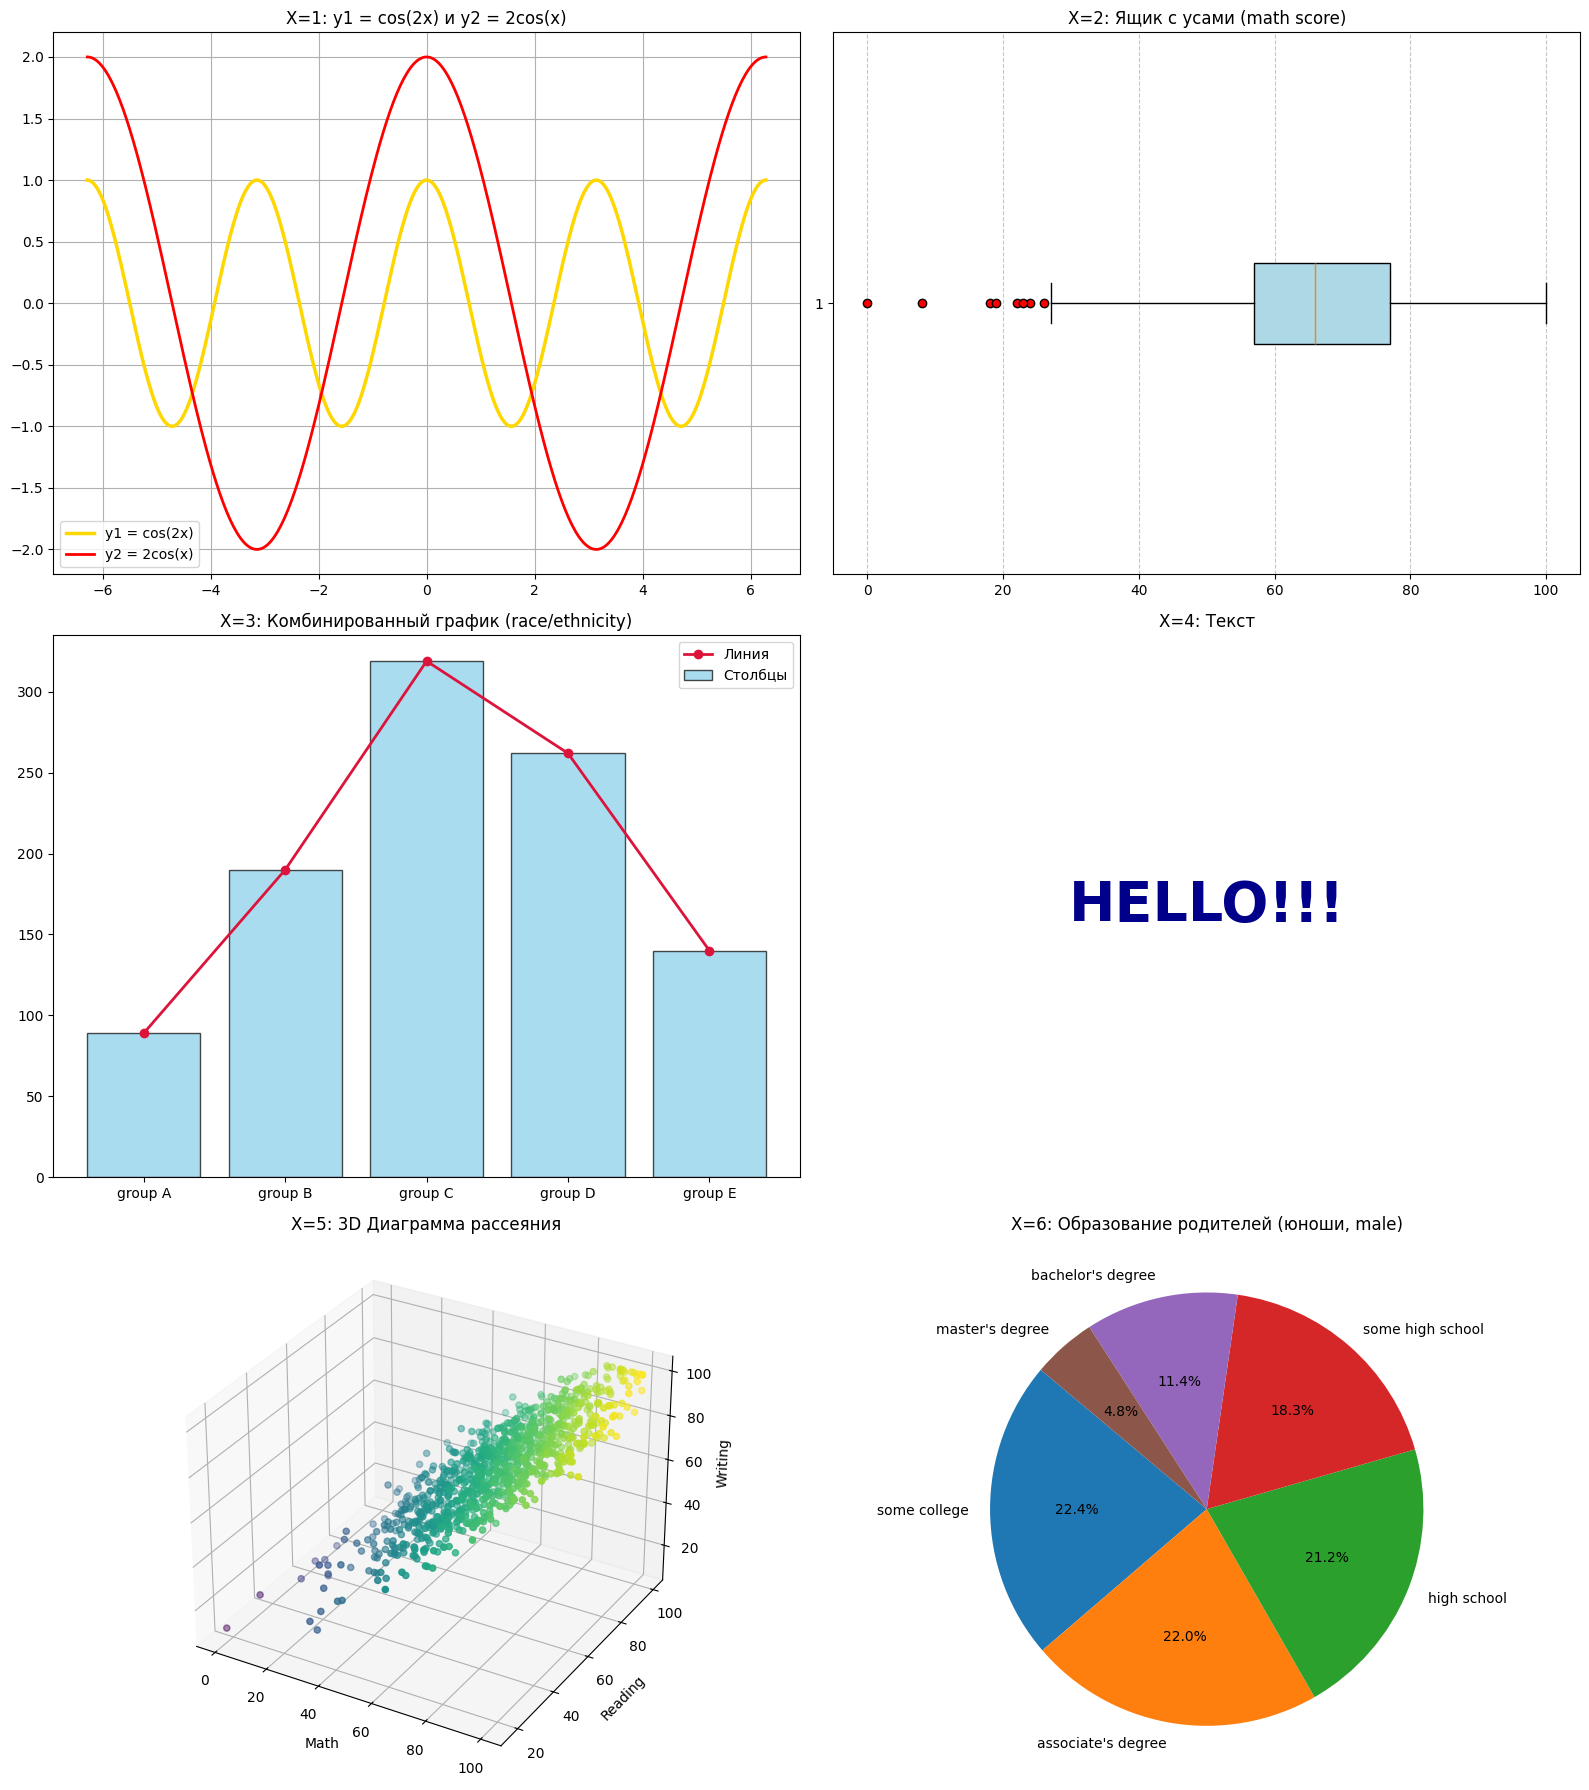

In [ ]:
fig = plt.figure(figsize=(16, 18))

# X=1 (321)
ax1 = plt.subplot(321)
x = np.linspace(-2 * np.pi, 2 * np.pi, 400)
ax1.plot(x, np.cos(2 * x), color='gold', linewidth=2.5, label='y1 = cos(2x)')
ax1.plot(x, 2 * np.cos(x), color='red', linewidth=2, label='y2 = 2cos(x)')
ax1.set_title('X=1: y1 = cos(2x) и y2 = 2cos(x)')
ax1.grid(True)
ax1.legend()

# X=2 (322)
ax2 = plt.subplot(322)
ax2.boxplot(df['math score'], vert=False, patch_artist=True,
            boxprops=dict(facecolor='lightblue'),
            flierprops=dict(marker='o', markerfacecolor='red'))
ax2.set_title('X=2: Ящик с усами (math score)')
ax2.grid(axis='x', linestyle='--', alpha=0.7)

# X=3 (323)
ax3 = plt.subplot(323)
rc = df['race/ethnicity'].value_counts().sort_index()
ax3.bar(rc.index, rc.values, color='skyblue', edgecolor='black', alpha=0.7, label='Столбцы')
ax3.plot(rc.index, rc.values, color='crimson', marker='o', linewidth=2, label='Линия')
ax3.set_title('X=3: Комбинированный график (race/ethnicity)')
ax3.legend()

# X=4 (324)
ax4 = plt.subplot(324)
ax4.text(0.5, 0.5, 'HELLO!!!', fontsize=40, fontweight='bold', color='darkblue', ha='center', va='center')
ax4.set_title('X=4: Текст')
ax4.axis('off')

# X=5 (325)
ax5 = plt.subplot(325, projection='3d')
ax5.scatter(df['math score'], df['reading score'], df['writing score'], c=df['math score'], cmap='viridis', s=20)
ax5.set_title('X=5: 3D Диаграмма рассеяния')
ax5.set_xlabel('Math')
ax5.set_ylabel('Reading')
ax5.set_zlabel('Writing')

# X=6 (326) — ИСПРАВЛЕНО (без cmap)
ax6 = plt.subplot(326)
male_edu = df[df['gender'] == 'male']['parental level of education'].value_counts()
ax6.pie(male_edu.values, labels=male_edu.index, autopct='%1.1f%%', startangle=140)
ax6.set_title('X=6: Образование родителей (юноши, male)')

plt.tight_layout()
plt.show()

**Выводы по блоку Matplotlib (ответы на вопросы задания):**
1. **X=1 (Функции):** На интервале $[-2\pi, 2\pi]$ функция $y_1 = \cos(2x)$ (желтая) имеет в два раза меньший период (сжата по оси $X$), а $y_2 = 2\cos(x)$ (красная) имеет в два раза большую амплитуду колебаний (растянута по оси $Y$ от $-2$ до $2$).
2. **X=2 («Ящик с усами» для `math score` — есть ли выбросы?):** **Да, выбросы есть.** Межквартильный размах (коробка) находится в диапазоне от $Q_1 = 57$ до $Q_3 = 77$ баллов (медиана — $66$). Слева от нижней границы нормы ($27$ баллов) расположены **8 экстремально низких значений (выбросов)**, отмеченных красными точками: `0, 8, 18, 19, 22, 23, 24, 26`.
3. **X=3 (Комбинированный график `race/ethnicity`):** Совмещение столбцов и линии наглядно показывает пик численности в группе `group C` (319 студентов) и плавный спад к группам `D` (262) и `E` (140). Минимум наблюдается в `group A` (89).
4. **X=4 (Текст):** Выведено отцентрированное текстовое сообщение `HELLO!!!` с отключенными координатными осями.
5. **X=5 (3D диаграмма рассеяния):** Точки в трехмерном пространстве (`Math`, `Reading`, `Writing`) вытянуты в плотное облако вдоль главной диагонали куба, что подтверждает сильную положительную взаимосвязь всех трех оценок.
6. **X=6 (Круговая диаграмма для юношей, `gender == 'male'`):** Среди родителей юношей преобладают категории `some college` (22.4%), `associate's degree` (22.0%) и `high school` (21.2%). Доля родителей с магистерской степенью (`master's degree`) минимальна — 4.8%.

### Блок 3. Анализ парных зависимостей и корреляций в Seaborn
Построение матриц диаграмм рассеяния (`pairplot`) для числовых столбцов с гистограммами и ядерной оценкой плотности распределения (`kde`) на главной диагонали, кластеризацией по признаку пола (`hue='gender'`), а также построение тепловой карты матрицы корреляций (`heatmap`).

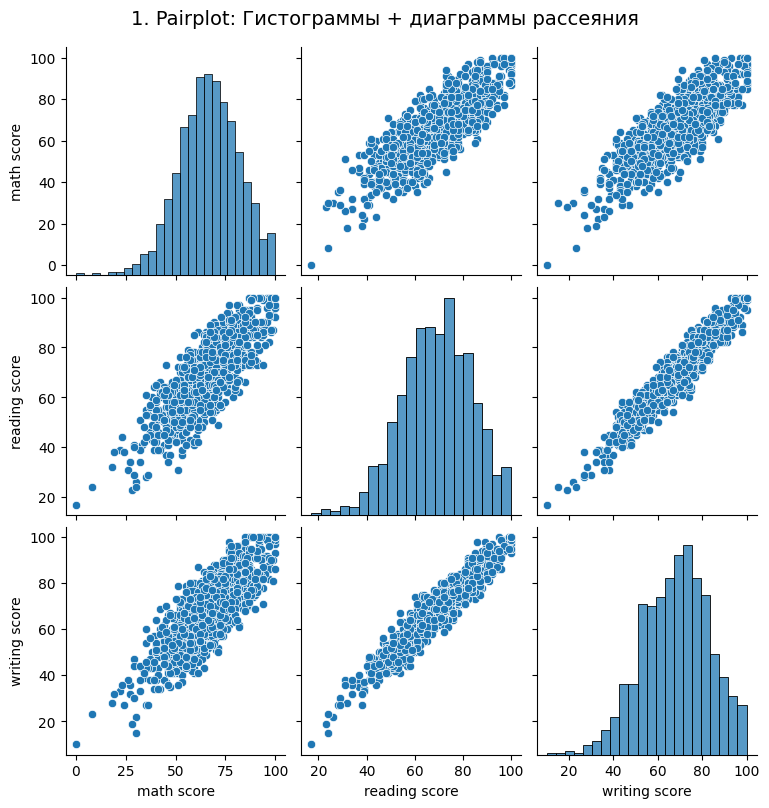

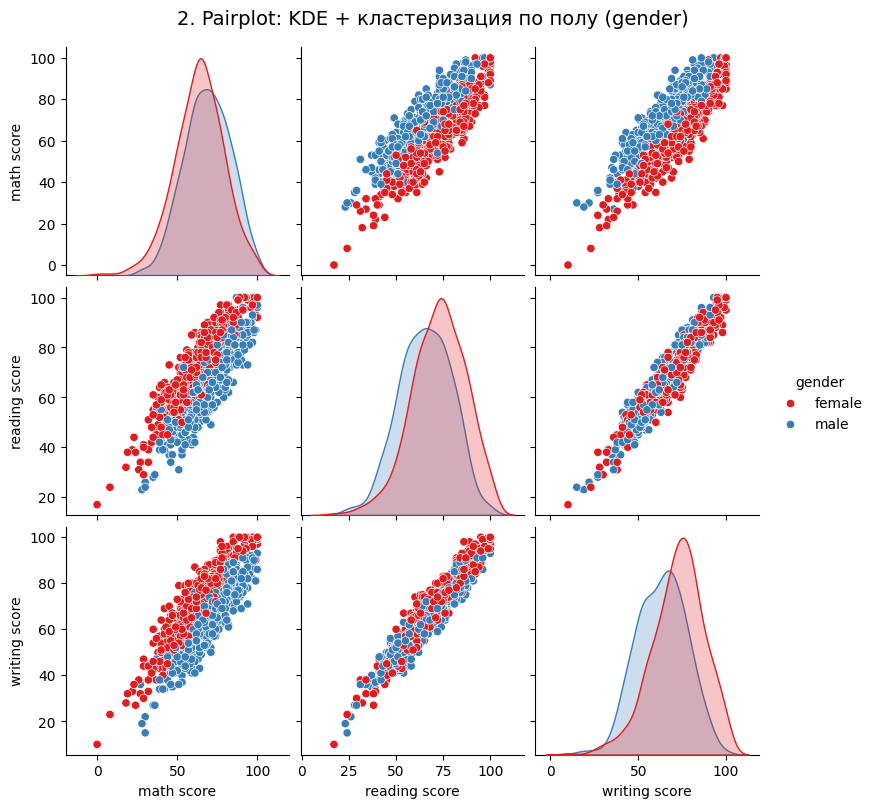

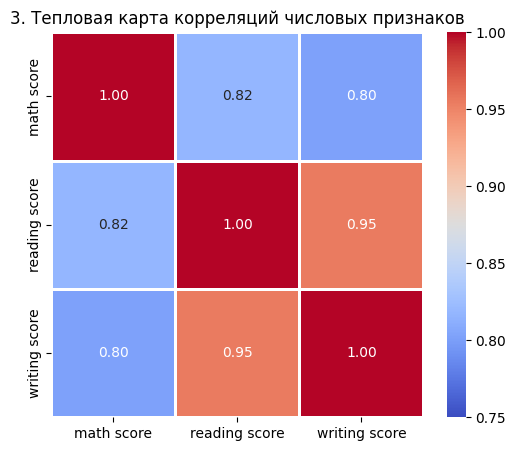

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Гистограммы по диагонали + диаграммы рассеяния для числовых столбцов
g1 = sns.pairplot(df, diag_kind='hist', height=2.6)
g1.fig.suptitle('1. Pairplot: Гистограммы + диаграммы рассеяния', y=1.03, fontsize=14)
plt.show()

# 2. KDE по диагонали + диаграммы рассеяния с кластеризацией по полу (hue='gender')
g2 = sns.pairplot(df, hue='gender', diag_kind='kde', palette='Set1', height=2.6)
g2.fig.suptitle('2. Pairplot: KDE + кластеризация по полу (gender)', y=1.03, fontsize=14)
plt.show()

# 3. Тепловая карта (heatmap) для числовых столбцов
plt.figure(figsize=(6, 5))
corr_matrix = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=1, vmin=0.75, vmax=1.0)
plt.title('3. Тепловая карта корреляций числовых признаков')
plt.show()

**Выводы по блоку Seaborn и общий итог работы:**
1. **Матрица рассеяния и гистограммы (`pairplot`, `diag_kind='hist'`):** Все парные графики рассеяния между баллами за математику (`math score`), чтение (`reading score`) и письмо (`writing score`) имеют выраженный линейный восходящий тренд. Студенты с высокими баллами по одному предмету стабильно показывают высокие результаты по остальным.
2. **Кластеризация по полу (`pairplot`, `hue='gender'`, `diag_kind='kde'`):** Ядерные оценки плотности (`KDE`) по диагонали и цветовое разделение точек выявляют четкие различия в успеваемости между юношами и девушками:
   * Распределение по математике (`math score`) у юношей (`male`) смещено вправо — их средний балл выше (`68.73` против `63.63` у девушек).
   * По чтению (`reading score`) и письму (`writing score`) кривые плотности девушек (`female`) заметно сдвинуты в область высоких значений (`72.61` и `72.47` против `65.47` и `63.31` у юношей).
3. **Тепловая карта (`heatmap`):** Коэффициенты линейной корреляции Пирсона подтверждают сильную положительную связь между всеми экзаменами:
   * Максимальная корреляция — между чтением и письмом (**0.95**).
   * Корреляция математики с чтением составляет **0.82**, а с письмом — **0.80**.

**Общее заключение по EDA:**
В ходе разведочного анализа изучена структура датасета `StudentsPerformance.csv` (1000 объектов, 8 признаков, пропусков нет), рассчитаны основные статистические метрики, с помощью «ящика с усами» выявлены 8 статистических выбросов в баллах по математике (значения ниже 27 баллов, включая минимум 0), а также установлены сильные линейные зависимости между результатами экзаменов и гендерная специфика распределения оценок.